# PDFT Calculation for H$_2$ with fractional electron numbers

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

Fragments do not have to hold an integer number of electrons: the *charge ensemble* takes the average number of electrons of each fragment,
`ensembles={'charge': {0: 1.4, 1: 0.6}}`, and `f4b` builds the ensemble from it, using the two integers around each number:

| fragment | electrons | members |
|---|---|---|
| 0 | 1.4 | H (1 electron, weight 0.6) + H$^-$ (2 electrons, weight 0.4) |
| 1 | 0.6 | no electrons (weight 0.4) + H (1 electron, weight 0.6) |

The two numbers must add up to the 2 electrons of H$_2$. An integer number means "no ensemble" for that fragment. `fcharge` is not needed.

In [2]:
sep = 1.4
mol = fgto.M(atom=f"""
    H {-0.5*sep} 0 0
    H {+0.5*sep} 0 0
""", unit='bohr', basis='cc-pvdz',
    fragments={0: [0], 1: [1]},                     # atom indices (0-based) of each fragment
    ensembles={'charge': {0: 1.4, 1: 0.6},          # average number of electrons of each fragment
               'spin': [0, 1]})                     # open-shell members averaged with their spin-flipped partner
print(mol)

my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

FragMole:
  Fragment 0: atoms=(0,) Z=1 members=[(1,0;w=0.3,flip=0.3), (1,1;w=0.4,flip=0)]
  Fragment 1: atoms=(1,) Z=1 members=[(0,0;w=0.4,flip=0), (1,0;w=0.3,flip=0.3)]


Eref = -1.15988035


---
## Do PDFT Calculations

### Functional Method

In [3]:
mf2 = pdft.RKS(mol, method='functional-T', maxiter=30, frag_symm='none')
mf2.kernel()
E_mf2, Df_mf2 = mf2.e_tot, mf2.make_rdm1()
nf_mf2 = D2n(Df_mf2[0]+Df_mf2[1], phi)

dE_mf2 = abs(Eref-E_mf2)
L1_mf2 = np.sum(np.abs(nf_mf2-nref)*w)
Nf_mf2 = np.sum(nf_mf2*w)
print(f"Energy difference (Ha): {dE_mf2:.3e}, Density error: {L1_mf2:.3e}")

P-DFT method=functional xc=PBE fxc=PBE nao=10 grid=72080


  it    1  Ef =    -0.7902823141  dEf =         nan  |dVp| = 5.718e-01


  it    2  Ef =    -0.7628906206  dEf =   2.739e-02  |dVp| = 2.980e-01


  it    3  Ef =    -0.7307528356  dEf =   3.214e-02  |dVp| = 1.937e-01


  it    4  Ef =    -0.7098857655  dEf =   2.087e-02  |dVp| = 1.522e-01


  it    5  Ef =    -0.6973222539  dEf =   1.256e-02  |dVp| = 1.339e-01


... (23 outputs left out)

  it   29  Ef =    -0.6717006139  dEf =   3.694e-04  |dVp| = 9.055e-02


  it   30  Ef =    -0.6713182983  dEf =   3.823e-04  |dVp| = 8.977e-02


Energy difference (Ha): 3.061e-05, Density error: 7.171e-02


/home/ulises/Documents/Research/PDFT_package_dev/f4b/f4b/pdft.py:425: UserWarning: P-DFT did not converge in 30 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


### Inversion Method

In [4]:
mf1 = pdft.RKS(mol, method='inversion', maxiter=20, frag_symm='none')
mf1.kernel()
E_mf1, Df_mf1 = mf1.e_tot, mf1.make_rdm1()
nf_mf1 = D2n(Df_mf1[0]+Df_mf1[1], phi)

dE_mf1 = abs(Eref-E_mf1)
L1_mf1 = np.sum(np.abs(nf_mf1-nref)*w)
Nf_mf1 = np.sum(nf_mf1*w)
print(f"Energy difference (Ha): {dE_mf1:.3e}, Density error: {L1_mf1:.3e}")

P-DFT method=inversion xc=PBE fxc=PBE nao=10 grid=72080


  it    1  Ef =    -0.7902823141  dEf =         nan  |dVp| = 5.797e-01


  it    2  Ef =    -0.7655533085  dEf =   2.473e-02  |dVp| = 3.408e-01


  it    3  Ef =    -0.7342776542  dEf =   3.128e-02  |dVp| = 2.352e-01


  it    4  Ef =    -0.7112437990  dEf =   2.303e-02  |dVp| = 1.762e-01


  it    5  Ef =    -0.6955893405  dEf =   1.565e-02  |dVp| = 1.425e-01


... (13 outputs left out)

  it   19  Ef =    -0.6599366180  dEf =   4.004e-04  |dVp| = 8.956e-02


  it   20  Ef =    -0.6595612048  dEf =   3.754e-04  |dVp| = 8.910e-02


Energy difference (Ha): 6.804e-04, Density error: 6.408e-02


/home/ulises/Documents/Research/PDFT_package_dev/f4b/f4b/pdft.py:425: UserWarning: P-DFT did not converge in 20 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


### Reference Method

In [5]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=30, frag_symm='none')
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

P-DFT method=reference xc=PBE fxc=PBE nao=10 grid=72080


  it    1  Ef =    -0.7902823141  dEf =         nan  |dVp| = 6.346e-02  L1 = 7.906e-01


  it    2  Ef =    -0.7873068180  dEf =   2.975e-03  |dVp| = 5.290e-02  L1 = 6.600e-01


  it    3  Ef =    -0.7816204522  dEf =   5.686e-03  |dVp| = 4.553e-02  L1 = 5.703e-01


  it    4  Ef =    -0.7754499983  dEf =   6.170e-03  |dVp| = 4.001e-02  L1 = 5.050e-01


  it    5  Ef =    -0.7695172149  dEf =   5.933e-03  |dVp| = 3.570e-02  L1 = 4.553e-01


... (22 outputs left out)

  it   28  Ef =    -0.7132365969  dEf =   1.004e-03  |dVp| = 9.117e-03  L1 = 1.830e-01


  it   29  Ef =    -0.7122846938  dEf =   9.519e-04  |dVp| = 8.795e-03  L1 = 1.800e-01


  it   30  Ef =    -0.7113812893  dEf =   9.034e-04  |dVp| = 8.494e-03  L1 = 1.771e-01


Energy difference (Ha): 5.398e-03, Density error: 1.771e-01


The three methods use the same fragments and weights. With different electron numbers on the two fragments the symmetry between them is
lost (`frag_symm='none'`): the partition potential has to polarize the fragments towards the target density.

---
## Plot densities and partition potential

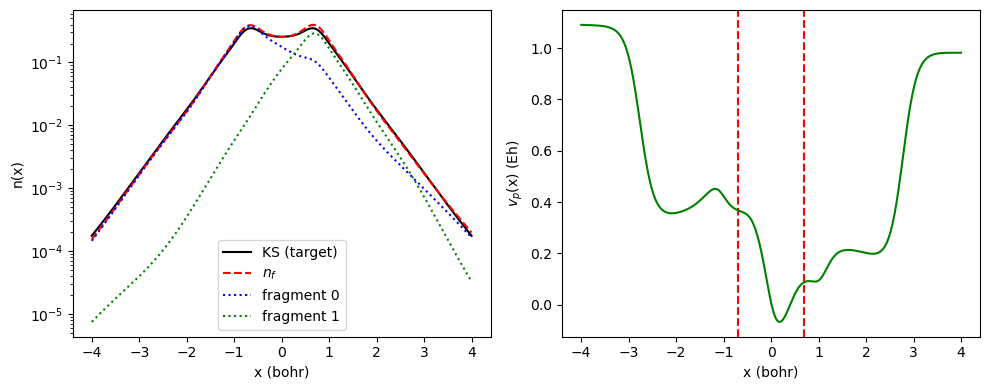

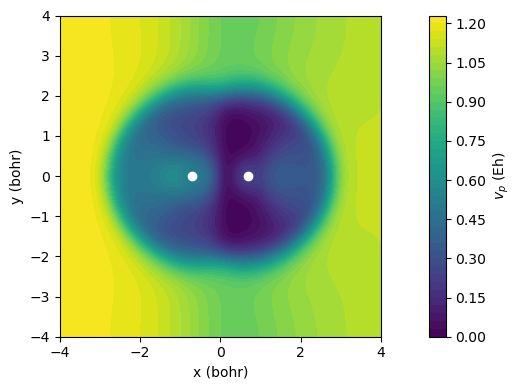

In [6]:
# # 1D plot along molecular axis
x = np.linspace(-4, 4, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf1.eval_density(line)                    # promolecular density
n_0 = mf1.eval_density(line, frag=0)            # fragment densities
n_1 = mf1.eval_density(line, frag=1)
vp  = mf1.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
ax[0].semilogy(x, n_0, 'b:', label='fragment 0')
ax[0].semilogy(x, n_1, 'g:', label='fragment 1')
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-4, 4, 160); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf1.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()